In [108]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
import problema_2 as p

# RUTA = "../images/Patentes/img01.png"
RUTA = "../images/extra/e4.png"
FACTOR = 6

In [109]:
# ------------------------------------------------------------
# Ayudas para graficar: cada llamada a mostrar() es UN paso (numerado solo)
# ------------------------------------------------------------
_paso = [0]

def mostrar(img, titulo, cmap="gray", vmin=None, vmax=None, figsize=(8, 4.5)):
    """Un gráfico por paso. Si la imagen tiene 3 canales se asume BGR (color de OpenCV)."""
    _paso[0] += 1
    plt.figure(figsize=figsize)
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.title(f"Paso {_paso[0]}: {titulo}", fontsize=11)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

def ampliar(img, factor=FACTOR):
    """Agranda sin suavizar y pasa a BGR para poder dibujar en color."""
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    return cv2.resize(img, None, fx=factor, fy=factor, interpolation=cv2.INTER_NEAREST)

def dibujar_caja(vis, c, color, factor=FACTOR):
    cv2.rectangle(vis, (c.x * factor, c.y * factor), ((c.x + c.w) * factor, (c.y + c.h) * factor), color, 1)

def recta(vis, punto, pendiente, ancho, color, factor=FACTOR):
    x0, y0 = punto
    cv2.line(vis, (0, int((y0 - pendiente * x0) * factor)),
             ((ancho - 1) * factor, int((y0 + pendiente * (ancho - 1 - x0)) * factor)), color, 1)

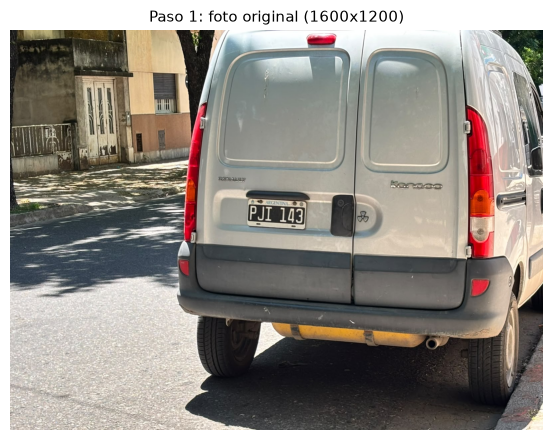

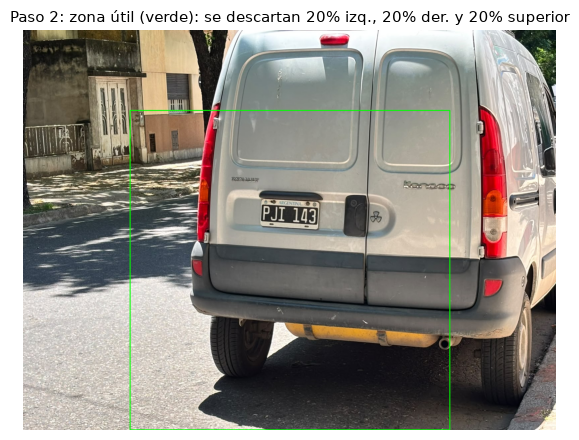

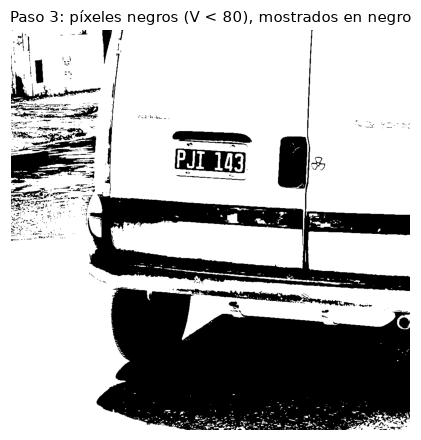

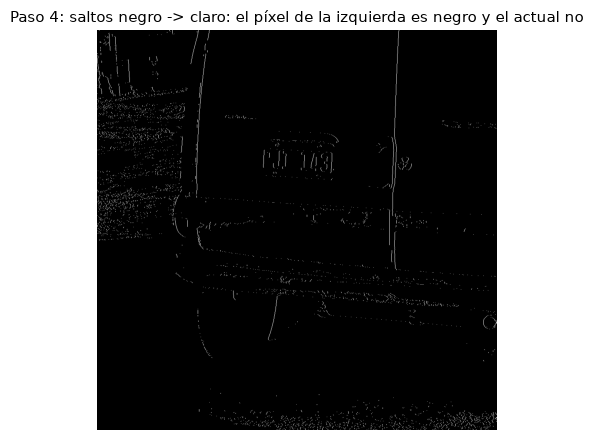

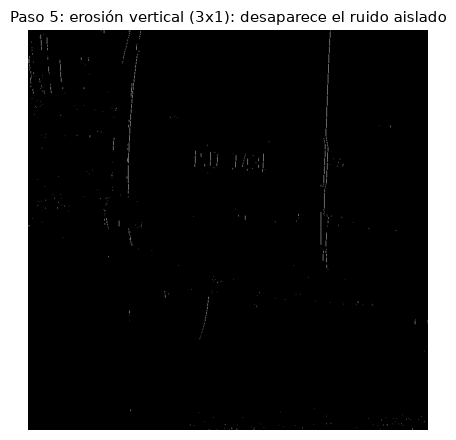

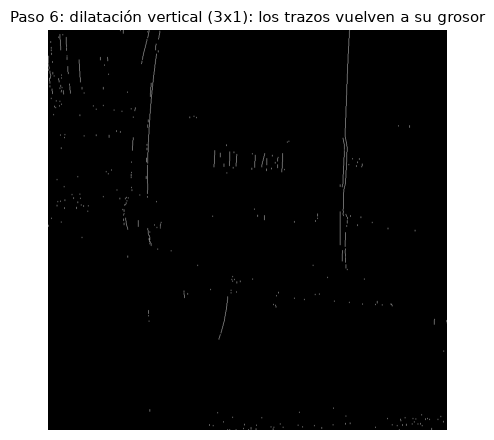

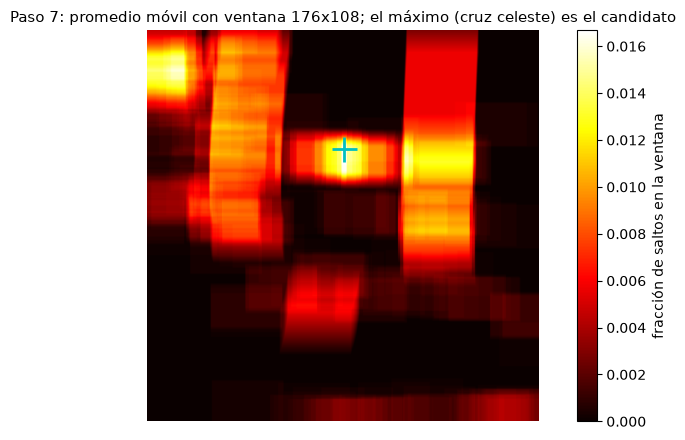

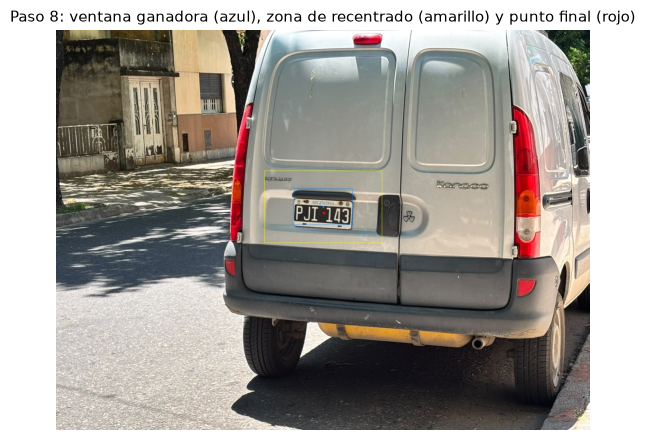

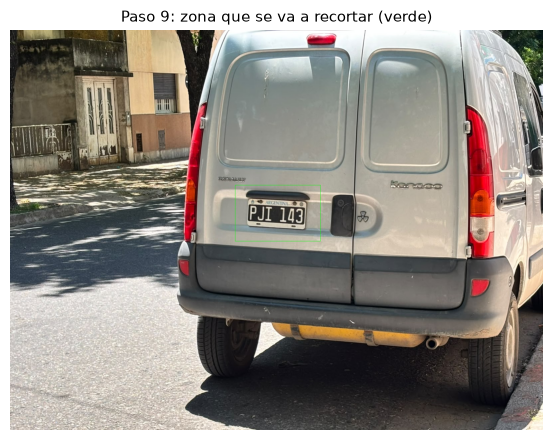

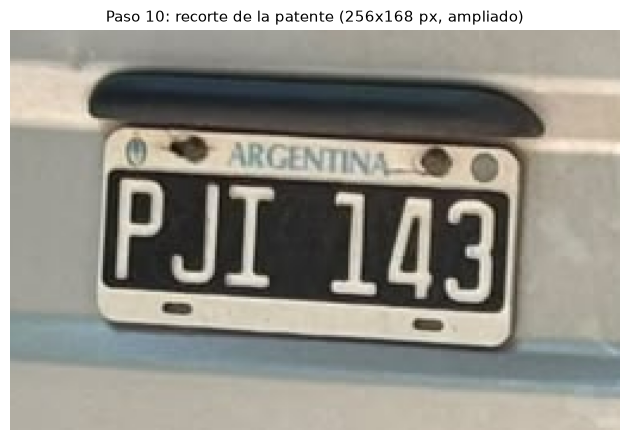

In [110]:
# ============================================================
# ETAPA 1: ENCONTRAR LA PATENTE EN LA FOTO
# ============================================================
img = cv2.imread(RUTA, cv2.IMREAD_COLOR)
h_img, w_img = img.shape[:2]
mostrar(img, f"foto original ({w_img}x{h_img})")

# --- zona útil: sin márgenes izquierdo, derecho y superior (ahí nunca hay patentes)
x0, x1 = int(p.MARGEN_IZQ * w_img), int((1 - p.MARGEN_DER) * w_img)
y0 = int(p.MARGEN_SUP * h_img)
roi = img[y0:, x0:x1]
vis = img.copy()
cv2.rectangle(vis, (x0, y0), (x1, h_img - 1), (0, 255, 0), 2)
mostrar(vis, "zona útil (verde): se descartan 20% izq., 20% der. y 20% superior")

# --- píxeles negros: brillo (canal V de HSV) menor a V_NEGRO
negro = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)[..., 2] < p.V_NEGRO
mostrar(negro, f"píxeles negros (V < {p.V_NEGRO}), mostrados en negro", cmap="gray_r")

# --- saltos negro -> claro (borde izquierdo de cada trazo claro)
saltos = p.mapa_transiciones(negro)
mostrar(saltos, "saltos negro -> claro: el píxel de la izquierda es negro y el actual no", vmin=0, vmax=1)

# --- erosión vertical: sobreviven los saltos que forman trazos verticales de >= ALTO_MIN_TRAZO px
saltos = cv2.erode(saltos, np.ones((p.ALTO_MIN_TRAZO, 1), np.uint8))
mostrar(saltos, f"erosión vertical ({p.ALTO_MIN_TRAZO}x1): desaparece el ruido aislado", vmin=0, vmax=1)

# --- dilatación: los trazos que sobrevivieron se vuelven a engrosar
saltos = cv2.dilate(saltos, np.ones((3, 1), np.uint8))
mostrar(saltos, "dilatación vertical (3x1): los trazos vuelven a su grosor", vmin=0, vmax=1)

# --- promedio móvil: qué fracción de cada ventana son saltos
W, H = int(p.VENTANA_W * w_img), int(p.VENTANA_H * h_img)
cantidad = cv2.blur(saltos.astype(np.float32), (W, H), borderType=cv2.BORDER_CONSTANT)
cy, cx = np.unravel_index(np.argmax(cantidad), cantidad.shape)
plt.figure(figsize=(8, 4.5))
_paso[0] += 1
plt.imshow(cantidad, cmap="hot"); plt.colorbar(label="fracción de saltos en la ventana")
plt.plot(cx, cy, "c+", markersize=18, markeredgewidth=2)
plt.title(f"Paso {_paso[0]}: promedio móvil con ventana {W}x{H}; el máximo (cruz celeste) es el candidato", fontsize=11)
plt.axis("off"); plt.tight_layout(); plt.show()

# --- recentrar: promedio de las posiciones de los saltos en una zona de 2W x 2H alrededor del máximo
ya, xa = max(0, cy - H), max(0, cx - W)
ys, xs = np.nonzero(saltos[ya:cy + H, xa:cx + W])
cy2, cx2 = int(ys.mean()) + ya, int(xs.mean()) + xa
vis = img.copy()
cv2.rectangle(vis, (xa + x0, ya + y0), (cx + W + x0, cy + H + y0), (0, 255, 255), 1)          # zona 2W x 2H (amarillo)
cv2.rectangle(vis, (cx + x0 - W // 2, cy + y0 - H // 2), (cx + x0 + W // 2, cy + y0 + H // 2), (255, 128, 0), 1)  # ventana ganadora (azul)
cv2.circle(vis, (cx + x0, cy + y0), 3, (255, 128, 0), -1)
cv2.circle(vis, (cx2 + x0, cy2 + y0), 4, (0, 0, 255), -1)                                      # punto final (rojo)
mostrar(vis, "ventana ganadora (azul), zona de recentrado (amarillo) y punto final (rojo)")

punto = (cx2 + x0, cy2 + y0)
assert punto == p.detectar_punto(img)[:2], "el paso a paso no coincide con detectar_punto()"

# --- recorte
recorte = p.recortar(img, punto)
vis = img.copy()
cw, ch = int(p.RECORTE_W * w_img), int(p.RECORTE_H * h_img)
cv2.rectangle(vis, (punto[0] - cw // 2, punto[1] - ch // 2), (punto[0] + cw // 2, punto[1] + ch // 2), (0, 255, 0), 1)
mostrar(vis, "zona que se va a recortar (verde)")
mostrar(ampliar(recorte), f"recorte de la patente ({recorte.shape[1]}x{recorte.shape[0]} px, ampliado)")

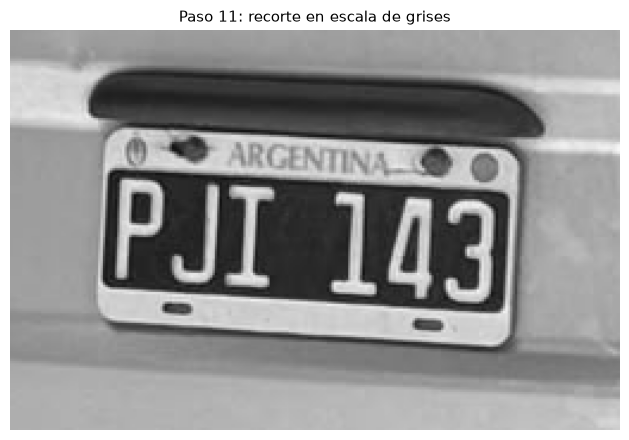

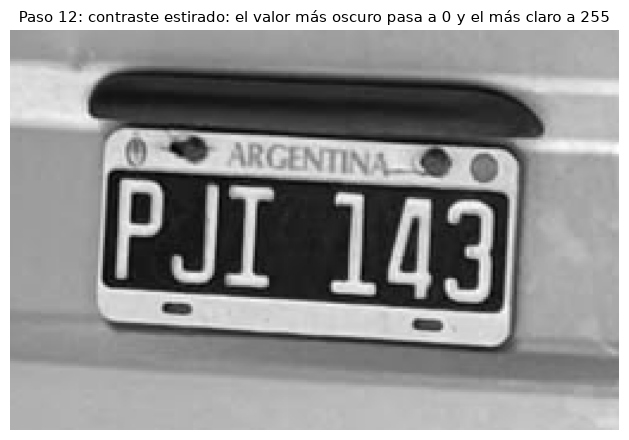

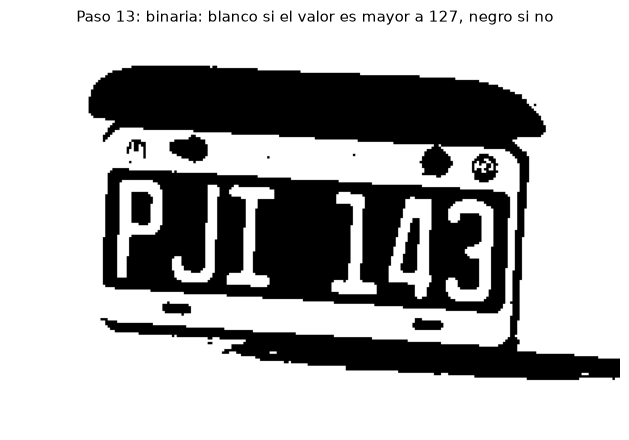

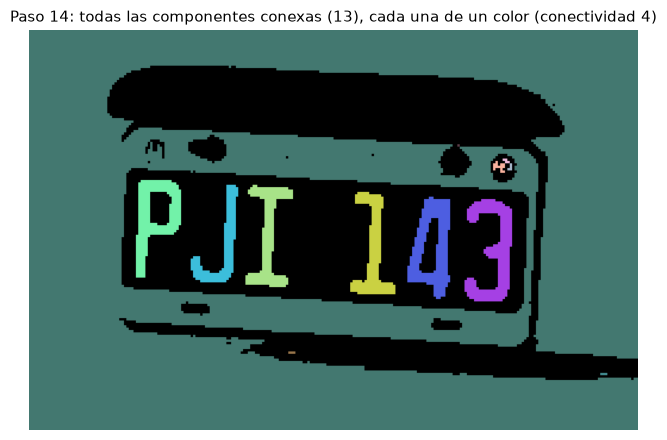

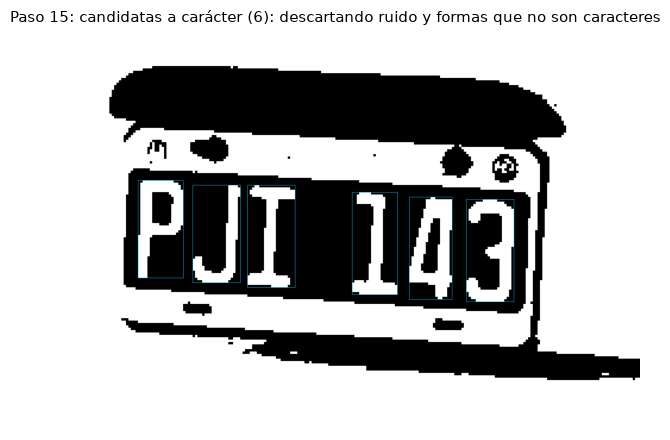

In [111]:
# ============================================================
# ETAPA 2: BINARIZAR Y BUSCAR CANDIDATOS A CARACTERES
# ============================================================
estirado, binaria = p.preparar_binaria(recorte)
alto, ancho = binaria.shape
mostrar(ampliar(cv2.cvtColor(recorte, cv2.COLOR_BGR2GRAY)), "recorte en escala de grises")
mostrar(ampliar(estirado), "contraste estirado: el valor más oscuro pasa a 0 y el más claro a 255")
mostrar(ampliar(binaria), f"binaria: blanco si el valor es mayor a {p.UMBRAL_BINARIO}, negro si no")

# --- todas las componentes conexas (cada una con un color distinto)
n, etiquetas, _, _ = cv2.connectedComponentsWithStats(binaria, connectivity=p.CONECTIVIDAD)
rng = np.random.default_rng(0)
colores = rng.integers(60, 255, size=(n, 3)).astype(np.uint8); colores[0] = 0      # el fondo queda negro
mostrar(ampliar(colores[etiquetas]), f"todas las componentes conexas ({n - 1}), cada una de un color (conectividad {p.CONECTIVIDAD})")

# --- candidatas: pasan los filtros de área, altura y forma
candidatas = p.componentes(binaria)
vis = ampliar(binaria)
for c in candidatas:
    dibujar_caja(vis, c, p.COLOR_CANDIDATA)
mostrar(vis, f"candidatas a carácter ({len(candidatas)}): descartando ruido y formas que no son caracteres")

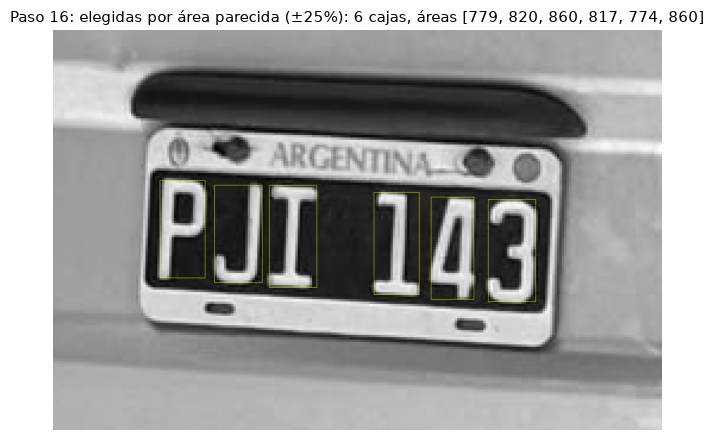

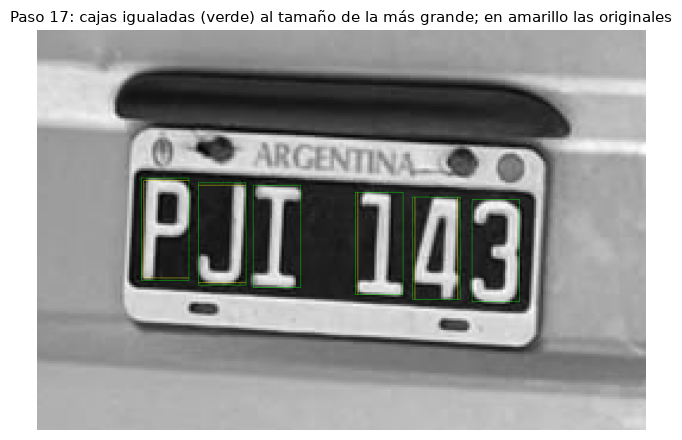

Se encontraron los 6 caracteres: no hace falta deducir ninguno.


In [112]:
# ============================================================
# ETAPA 3: ELEGIR, IGUALAR Y (SI HACE FALTA) DEDUCIR LOS QUE FALTAN
# ============================================================
originales = p.cajas_de_area_similar(candidatas)
vis = ampliar(estirado)
for c in originales:
    dibujar_caja(vis, c, p.COLOR_ORIGINAL)
mostrar(vis, f"elegidas por área parecida (±{int(p.TOL_AREA * 100)}%): {len(originales)} cajas, áreas {[c.area for c in originales]}")

encontradas = p.igualar_cajas(originales)
vis = ampliar(estirado)
for c in originales:
    dibujar_caja(vis, c, p.COLOR_ORIGINAL)           # amarillo: como se detectaron
for c in encontradas:
    dibujar_caja(vis, c, p.COLOR_ENCONTRADA)         # verde: todas del tamaño de la más grande
mostrar(vis, "cajas igualadas (verde) al tamaño de la más grande; en amarillo las originales")

proyectadas = []
if len(encontradas) == p.N_CARACTERES:
    print(f"Se encontraron los {p.N_CARACTERES} caracteres: no hace falta deducir ninguno.")
elif len(encontradas) < 2:
    print("Hay menos de 2 caracteres: no alcanza para calcular la inclinación.")
else:
    mitad = ancho / 2
    izq = [c for c in encontradas if c.cx < mitad]
    der = [c for c in encontradas if c.cx >= mitad]
    vis = ampliar(estirado)
    for c in encontradas:
        dibujar_caja(vis, c, p.COLOR_ENCONTRADA)
    cv2.line(vis, (int(mitad * FACTOR), 0), (int(mitad * FACTOR), alto * FACTOR), (255, 255, 255), 1)
    mostrar(vis, f"línea del 50% (blanca): {len(izq)} caracteres a la izquierda y {len(der)} a la derecha (debería haber 3 y 3)")

    pend = p.pendiente_entre(encontradas[0], encontradas[-1])
    ref = encontradas[0]
    vis = ampliar(estirado)
    for c in encontradas:
        dibujar_caja(vis, c, p.COLOR_ENCONTRADA)
    recta(vis, (ref.cx, ref.cy), pend, ancho, p.COLOR_CENTROS)
    mostrar(vis, f"recta por los centros de la primera y la última caja: inclinación {np.degrees(np.arctan(pend)):.1f}°")

    recta(vis, (ref.x, ref.y), pend, ancho, p.COLOR_TECHO)
    recta(vis, (ref.x + ref.w, ref.y + ref.h), pend, ancho, p.COLOR_PISO)
    mostrar(vis, "techo (celeste) y piso (magenta): misma inclinación, desde las esquinas de la primera caja")

    pend, proyectadas = p.completar_caracteres(encontradas, ancho)
    for q in proyectadas:
        cv2.rectangle(vis, (int(q.x0 * FACTOR), int(q.y0 * FACTOR)), (int(q.x1 * FACTOR), int(q.y1 * FACTOR)), p.COLOR_PROYECTADA, 1)
    detalle = ", ".join(f"{q.lado}: falta {q.motivo}" for q in proyectadas) or "ninguna mitad con exactamente 2 caracteres: no se proyecta"
    mostrar(vis, f"caja deducida (naranja) -> {detalle}")

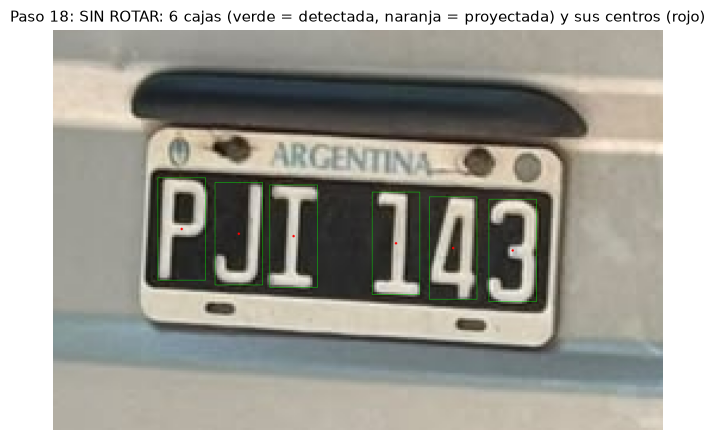

In [113]:
# ============================================================
# RESULTADO SIN ROTAR (aquí termina la DETECCIÓN: lo de la etapa 2 y 3 no cambia)
# ============================================================
cajas = sorted([(c.x, c.y, c.x + c.w, c.y + c.h, "detectada") for c in encontradas] +
               [(q.x0, q.y0, q.x1, q.y1, "proyectada") for q in proyectadas])
centros = np.array([((a + c) / 2, (b + d) / 2) for a, b, c, d, _ in cajas])
color_de = lambda tipo: p.COLOR_PROYECTADA if tipo == "proyectada" else p.COLOR_ENCONTRADA

def poligono(vis, esq, color):
    """Dibuja un polígono (lista de esquinas en coordenadas del recorte) sobre la imagen ampliada."""
    cv2.polylines(vis, [np.array([(int(round(x * FACTOR)), int(round(y * FACTOR))) for x, y in esq], np.int32)], True, color, 1)

vis = ampliar(recorte)
for x_a, y_a, x_b, y_b, tipo in cajas:
    poligono(vis, p.esquinas(x_a, y_a, x_b, y_b), color_de(tipo))
for cx_, cy_ in centros:
    cv2.circle(vis, (int(round(cx_ * FACTOR)), int(round(cy_ * FACTOR))), 3, p.COLOR_CENTROS, -1)
mostrar(vis, f"SIN ROTAR: {len(cajas)} cajas (verde = detectada, naranja = proyectada) y sus centros (rojo)")

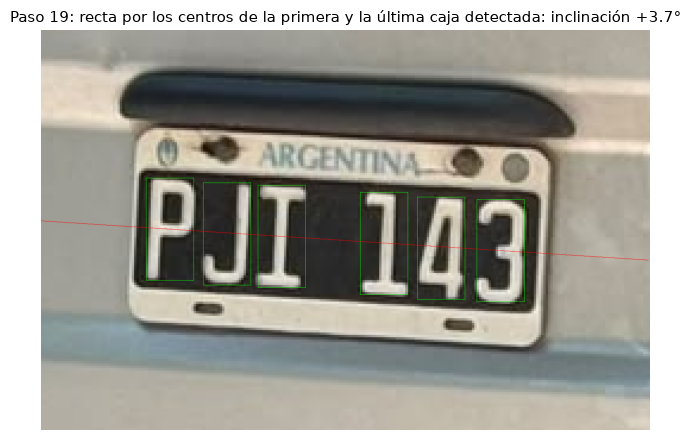

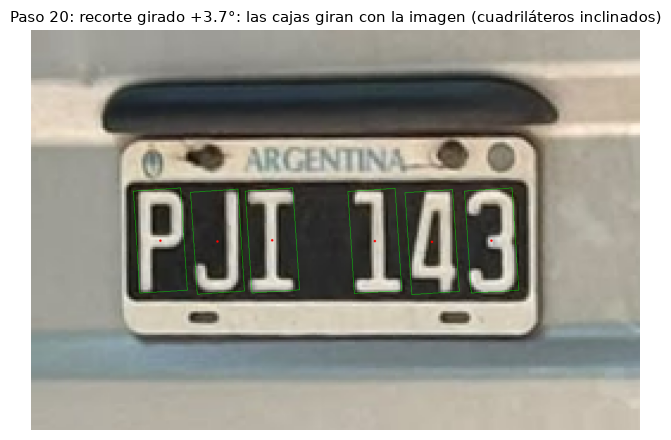

pendiente de la recta primera-última tras girar: +0.0000  (debe ser ~0)
desvío vertical de cada centro respecto de la fila (px): [-0.2   0.25 -0.24 -0.03  0.42 -0.2 ]


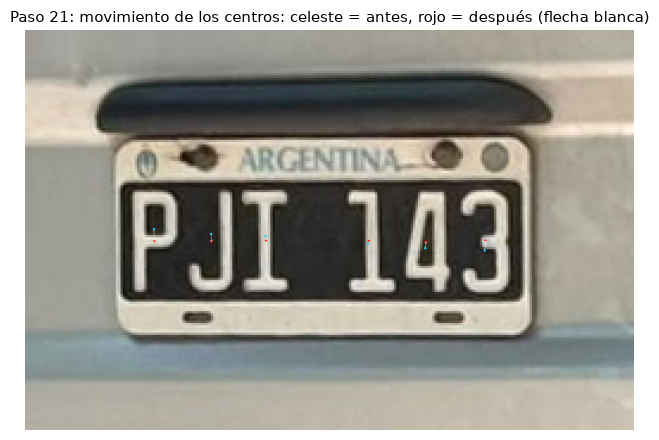

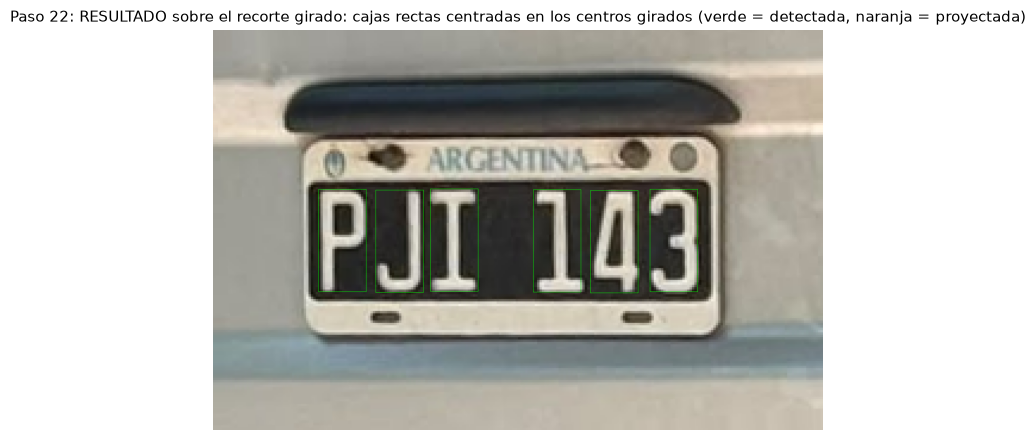

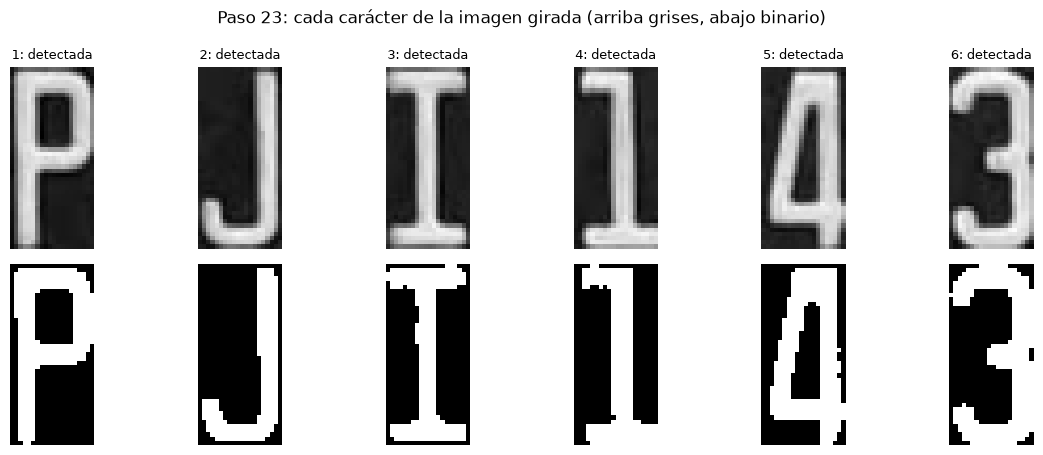

In [114]:
# ============================================================
# ETAPA 4: ENDEREZAR. Se gira el recorte y, con la MISMA matriz, las cajas
# ============================================================
angulo = p.angulo_por_centros(encontradas)      # recta por los centros de la primera y la última caja detectada
if angulo is None:
    print("Hay menos de 2 caracteres detectados: no se puede calcular el ángulo, no se gira.")
else:
    pend = np.tan(np.radians(angulo))
    ref = encontradas[0]
    vis = ampliar(recorte)
    for x_a, y_a, x_b, y_b, tipo in cajas:
        poligono(vis, p.esquinas(x_a, y_a, x_b, y_b), color_de(tipo))
    recta(vis, (ref.cx, ref.cy), pend, ancho, p.COLOR_CENTROS)
    mostrar(vis, f"recta por los centros de la primera y la última caja detectada: inclinación {angulo:+.1f}°")

    M = p.matriz_giro(angulo, ancho, alto)                 # giro alrededor del centro del recorte
    rotado = p.girar(recorte, M)
    estirado_rot = p.girar(estirado, M)
    binaria_rot = np.where(estirado_rot > p.UMBRAL_BINARIO, 255, 0).astype(np.uint8)
    centros_g = p.transformar_puntos(M, centros)           # los centros se mueven como los píxeles

    vis = ampliar(rotado)
    for x_a, y_a, x_b, y_b, tipo in cajas:
        poligono(vis, p.transformar_puntos(M, p.esquinas(x_a, y_a, x_b, y_b)), color_de(tipo))
    for cx_, cy_ in centros_g:
        cv2.circle(vis, (int(round(cx_ * FACTOR)), int(round(cy_ * FACTOR))), 3, p.COLOR_CENTROS, -1)
    mostrar(vis, f"recorte girado {angulo:+.1f}°: las cajas giran con la imagen (cuadriláteros inclinados)")

    pend_g = (centros_g[-1][1] - centros_g[0][1]) / (centros_g[-1][0] - centros_g[0][0])
    print(f"pendiente de la recta primera-última tras girar: {pend_g:+.4f}  (debe ser ~0)")
    print("desvío vertical de cada centro respecto de la fila (px):", np.round(centros_g[:, 1] - centros_g[:, 1].mean(), 2))

    vis = ampliar(rotado)
    for (a, b), (a2, b2) in zip(centros, centros_g):
        cv2.circle(vis, (int(round(a * FACTOR)), int(round(b * FACTOR))), 3, p.COLOR_CANDIDATA, -1)        # antes
        cv2.circle(vis, (int(round(a2 * FACTOR)), int(round(b2 * FACTOR))), 3, p.COLOR_CENTROS, -1)        # después
        cv2.arrowedLine(vis, (int(round(a * FACTOR)), int(round(b * FACTOR))),
                        (int(round(a2 * FACTOR)), int(round(b2 * FACTOR))), (255, 255, 255), 1, tipLength=0.25)
    mostrar(vis, "movimiento de los centros: celeste = antes, rojo = después (flecha blanca)")

    # cajas rectas del mismo tamaño, centradas en los centros girados: con estas se recorta cada carácter
    cajas_g = [(cx_ - (c - a) / 2, cy_ - (d - b) / 2, cx_ + (c - a) / 2, cy_ + (d - b) / 2, tipo)
               for (a, b, c, d, tipo), (cx_, cy_) in zip(cajas, centros_g)]
    vis = ampliar(rotado)
    for x_a, y_a, x_b, y_b, tipo in cajas_g:
        poligono(vis, p.esquinas(x_a, y_a, x_b, y_b), color_de(tipo))
    mostrar(vis, "RESULTADO sobre el recorte girado: cajas rectas centradas en los centros girados "
                 "(verde = detectada, naranja = proyectada)")

    # comprobación: el paso a paso coincide con p.analizar_recorte (el mismo código que usa el .py)
    ref_py = p.analizar_recorte(recorte)
    assert abs(ref_py.giro.angulo - angulo) < 1e-9 and np.allclose(ref_py.giro.centros_girados, centros_g), \
        "el paso a paso no coincide con analizar_recorte()"

    # ------------------------------------------------------------
    # CADA CARÁCTER POR SEPARADO, RECORTADO DE LA IMAGEN GIRADA
    # ------------------------------------------------------------
    _paso[0] += 1
    fig, ejes = plt.subplots(2, max(len(cajas_g), 1), figsize=(2.0 * max(len(cajas_g), 1), 4.6), squeeze=False)
    for j, (x_a, y_a, x_b, y_b, tipo) in enumerate(cajas_g):
        a, b = max(0, int(round(x_a))), max(0, int(round(y_a)))
        c_, d = min(ancho, int(round(x_b))), min(alto, int(round(y_b)))
        ejes[0, j].imshow(estirado_rot[b:d, a:c_], cmap="gray", vmin=0, vmax=255)
        ejes[1, j].imshow(binaria_rot[b:d, a:c_], cmap="gray", vmin=0, vmax=255)
        ejes[0, j].set_title(f"{j + 1}: {tipo}", fontsize=9, color="darkorange" if tipo == "proyectada" else "black")
        ejes[0, j].axis("off"); ejes[1, j].axis("off")
    fig.suptitle(f"Paso {_paso[0]}: cada carácter de la imagen girada (arriba grises, abajo binario)")
    plt.tight_layout(); plt.show()